# Payload imaging (R2) and geolocation (R3) — EmberSeeker

Evaluates **R2 (detection)** and **R3 (geolocation)** for the two candidates:

| Candidate | Repeat | Altitude | Architecture |
|---|---|---|---|
| **B0** | 15 revs / 1 day | ~567 km | Single satellite |
| **B1** | 134 revs / 9 days | ~601.5 km | 3-satellite constellation |

R2 and R3 live together because they share one optical chain — altitude, nadir GSD, η_acc,
off-nadir pixel stretch — and R3's threshold **is** one nadir GSD from R2. Splitting them
would duplicate that chain and let the two drift apart.

**Scope.** R1 access is in `orbit_planning.ipynb`; requirement thresholds and their basis
are in `reqs.ipynb`.

**R2 is evaluated geometrically.** There is no radiometric model in this repository, and the
slide 8 payload analysis was done outside it. Rather than rebuild Planck radiance, pixel
fill and noise here — which would duplicate that work and risk disagreeing with it — this
notebook computes the **pixel footprint** from lecture geometry and scales slide 8's
reported minimum detectable area by pixel area. Section 3.1 validates that scaling against
slide 8's own two data points and against slide 16's sensitivity result.

**Model.** Spherical Earth, pinhole optics, small-angle error propagation, zero-mean
independent errors combined in root-sum-square. Week 10 (access geometry, optics) and
Week 11 (measurement and geolocation).

## 1 · Setup and inputs

In [1]:
import sys, math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path.cwd()))
import eo_toolkit as eo

pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 120)
print('eo_toolkit', eo.__version__)

SAVE_OUTPUTS = True
OUT_DIR = Path('outputs/payload_geolocation')
if SAVE_OUTPUTS:
    OUT_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    if SAVE_OUTPUTS:
        fig.savefig(OUT_DIR / f'{name}.png', dpi=200, bbox_inches='tight', facecolor='white')

def save_table(df, name):
    if SAVE_OUTPUTS:
        df.to_csv(OUT_DIR / f'{name}.csv')

ROWS = []
def record(rid, quantity, value, tier, basis, lecture=''):
    ROWS.append(dict(ID=rid, Quantity=quantity, Value=value, Tier=tier,
                     Basis=basis, Lecture=lecture))

eo_toolkit N2.4


In [2]:
# ---------------- Candidate orbits (same selection as orbit_planning) -------
B0_JK, B1_JK = (15, 1), (134, 9)
ALT = {lab: eo.repeat_solution(*jk)['h_km'] for lab, jk in (('B0', B0_JK), ('B1', B1_JK))}
INC = {lab: eo.repeat_solution(*jk)['inc_deg'] for lab, jk in (('B0', B0_JK), ('B1', B1_JK))}

# ---------------- Payload (comparator-referenced, fixed optics) -------------
H_COMPARATOR_KM  = 600.0   # FireSat Protoflight reference altitude [km]
GSD_NADIR_COMP_M = 50.0    # MWIR nadir GSD at the comparator altitude [m]
SWATH_COMPARATOR = 1500.0  # comparator swath [km] at 600 km
GSD_CROSS_CAP_M  = 100.0   # cross-track GSD cap that defines eta_acc [m]
PITCH_UM         = 15.0    # detector pixel pitch [um]
APERTURE_M       = 0.10    # entrance aperture [m]
WAVELENGTH_NM    = 3700.0  # MWIR fire channel centre [nm]

# ---------------- R2 reference point, taken from slide 8 --------------------
AMIN_REF_M2       = 8.8    # minimum detectable fire area at nadir [m^2], 50 m GSD
AMIN_REF_PIXEL_M2 = 50.0 ** 2
AMIN_EDGE_SLIDE8  = 24.1   # slide 8's own edge value, used only to validate the scaling
AMIN_DEGRADED_M2  = 63.8   # slide 16: 345 K ground, 4 K clutter, at the 100 m-cap edge pixel
A_FIRE_REQ_M2     = 25.0   # R2 threshold: minimum detectable fire area [m^2]

# ---------------- R3 error budget inputs (datasheet / heritage) -------------
ARCSEC = math.radians(1/3600)       # rad per arcsecond
BUDGET = {
    'initial': dict(attitude_as=10.0, mount_as=7.0),   # COTS star tracker, heritage mount
    'refined': dict(attitude_as=2.0,  mount_as=2.0),   # better tracker + on-orbit calibration
}
POS_PER_AXIS_M = 3.5       # horizontal orbit position knowledge, per axis [m]
TIMING_S       = 1.0e-3    # timing knowledge [s]
DEM_VERT_M     = 4.0       # DEM vertical RMSE [m]

print('Altitudes:', {k: round(v, 2) for k, v in ALT.items()})

Altitudes: {'B0': 567.03, 'B1': 601.54}


## 2 · Imaging geometry: GSD and η_acc → **slides 7, 8**

Pinhole sampling gives $\mathrm{GSD} = h\,p/f$ (Week 10). Both candidates carry the **same**
payload, so $f$ is fixed and the nadir GSD scales linearly with altitude from the
comparator's 50 m at 600 km.

η_acc is the largest view angle whose cross-track GSD stays within the 100 m cap, capped by
the payload half-FOV and the horizon. Off-nadir the pixel stretches as
$\mathrm{GSD}_{along} = \mathrm{GSD}\,R_s/h$ across range, and
$\mathrm{GSD}_{cross} = \mathrm{GSD}_{along}/\sin\varepsilon$ with the surface tilt.

In [3]:
def half_fov_from_swath(h_km, swath_km):
    '''Nadir angle of the swath edge for a given swath at a given altitude [deg].'''
    gamma = (swath_km / 2) / eo.R_E
    return math.degrees(math.atan2(math.sin(gamma), (eo.R_E + h_km) / eo.R_E - math.cos(gamma)))

ETA_EDGE = half_fov_from_swath(H_COMPARATOR_KM, SWATH_COMPARATOR)   # fixed hardware half-FOV
FOCAL_M = eo.focal_length_for(H_COMPARATOR_KM, PITCH_UM, GSD_NADIR_COMP_M)
print(f'Fixed optics: f = {FOCAL_M*100:.2f} cm, half-FOV = {ETA_EDGE:.3f} deg '
      f'(full FOV {2*ETA_EDGE:.2f} deg)')

def eta_for_cap(h_km, gsd_nadir_m, cap_m, eta_hi_deg):
    '''Largest view angle [deg] whose cross-track GSD stays within cap_m.'''
    if eo.off_nadir_gsd(h_km, gsd_nadir_m, eta_hi_deg)['gsd_cross_m'] <= cap_m:
        return eta_hi_deg
    lo, hi = 0.0, eta_hi_deg
    for _ in range(80):
        mid = 0.5 * (lo + hi)
        if eo.off_nadir_gsd(h_km, gsd_nadir_m, mid)['gsd_cross_m'] <= cap_m:
            lo = mid
        else:
            hi = mid
    return lo

def geometry(h_km):
    '''All altitude-dependent imaging quantities for one candidate.'''
    gsd0 = eo.gsd_from_optics(h_km, PITCH_UM, FOCAL_M)['gsd_m']      # = 50 * h / 600
    rho = eo.earth_angular_radius(h_km)
    eta_cap = eta_for_cap(h_km, gsd0, GSD_CROSS_CAP_M, min(ETA_EDGE, rho - 1e-6))
    eta_acc = min(eta_cap, ETA_EDGE, rho - 1e-6)
    limiter = ('GSD cap' if eta_acc == eta_cap else
               'half-FOV' if eta_acc == ETA_EDGE else 'horizon')
    g = eo.access_geometry(h_km, eta_deg=eta_acc)
    s = eo.off_nadir_gsd(h_km, gsd0, eta_acc)
    diff = eo.diffraction_limit(h_km, APERTURE_M, WAVELENGTH_NM)
    return dict(h_km=round(h_km, 2), gsd_nadir_m=round(gsd0, 3), rho_deg=round(rho, 3),
                eta_edge_deg=round(ETA_EDGE, 3), eta_cap_deg=round(eta_cap, 3),
                eta_acc_deg=round(eta_acc, 3), limited_by=limiter,
                elevation_deg=round(g['eps'], 2), incidence_deg=round(90 - g['eps'], 2),
                slant_km=round(g['R_s'], 1),
                gsd_along_m=round(s['gsd_along_m'], 1), gsd_cross_m=round(s['gsd_cross_m'], 1),
                pixel_nadir_m2=round(gsd0**2, 0),
                pixel_edge_m2=round(s['gsd_along_m'] * s['gsd_cross_m'], 0),
                usable_swath_km=round(2 * g['ground_reach'], 1),
                rayleigh_m=round(diff['x_diff_m'], 2),
                rayleigh_over_gsd=round(diff['x_diff_m'] / gsd0, 3))

GEOM = {lab: geometry(ALT[lab]) for lab in ('B0', 'B1')}
GEOM_TABLE = pd.DataFrame(GEOM)
display(GEOM_TABLE)
save_table(GEOM_TABLE, 'imaging_geometry')

Fixed optics: f = 18.00 cm, half-FOV = 49.281 deg (full FOV 98.56 deg)


,B0,B1
h_km,567.03,601.54
gsd_nadir_m,47.253,50.128
rho_deg,66.687,66.038
eta_edge_deg,49.281,49.281
eta_cap_deg,42.874,41.231
eta_acc_deg,42.874,41.231
limited_by,GSD cap,GSD cap
elevation_deg,42.19,43.84
incidence_deg,47.81,46.16
slant_km,806.0,831.2


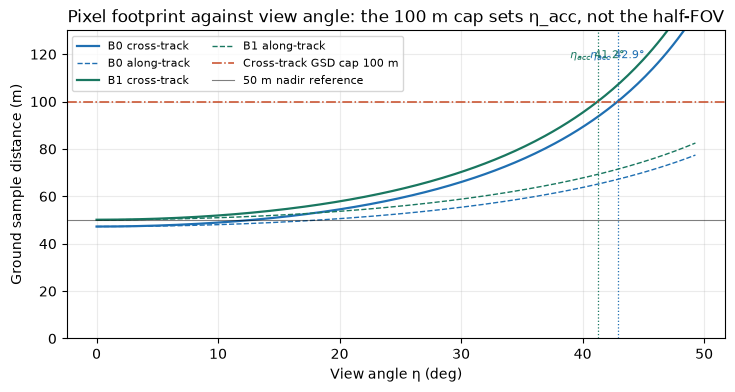

In [4]:
# GSD against view angle, with the 100 m cap and eta_acc marked  -> slide 8
fig, ax = plt.subplots(figsize=(8.5, 4))
for lab, col in (('B0', '#1f6fb2'), ('B1', '#197760')):
    h, g0 = ALT[lab], GEOM[lab]['gsd_nadir_m']
    etas = np.linspace(0, min(ETA_EDGE, eo.earth_angular_radius(h) - 1e-3), 240)
    cross = [eo.off_nadir_gsd(h, g0, e)['gsd_cross_m'] for e in etas]
    along = [eo.off_nadir_gsd(h, g0, e)['gsd_along_m'] for e in etas]
    ax.plot(etas, cross, color=col, lw=1.6, label=f'{lab} cross-track')
    ax.plot(etas, along, color=col, lw=1.0, ls='--', label=f'{lab} along-track')
    ax.axvline(GEOM[lab]['eta_acc_deg'], color=col, lw=.9, ls=':')
    ax.annotate(f"$\\eta_{{acc}}$ {GEOM[lab]['eta_acc_deg']:.1f}°",
                (GEOM[lab]['eta_acc_deg'], 118), color=col, fontsize=8, ha='center')
ax.axhline(GSD_CROSS_CAP_M, color='#c74924', lw=1.1, ls='-.',
           label=f'Cross-track GSD cap {GSD_CROSS_CAP_M:.0f} m')
ax.axhline(GSD_NADIR_COMP_M, color='k', lw=.8, alpha=.5, label='50 m nadir reference')
ax.set_xlabel('View angle η (deg)'); ax.set_ylabel('Ground sample distance (m)')
ax.set_ylim(0, 130); ax.grid(alpha=.25); ax.legend(fontsize=8, ncol=2, loc='upper left')
ax.set_title('Pixel footprint against view angle: the 100 m cap sets η_acc, not the half-FOV')
save_fig(fig, 'gsd_vs_view_angle'); plt.show()

In [5]:
for lab in ('B0', 'B1'):
    g = GEOM[lab]
    record('R2', f'Nadir GSD ({lab})', f"{g['gsd_nadir_m']:.2f} m", 'Calculated',
           'Pinhole GSD = h p / f with fixed optics, scaled from the comparator', 'Wk10')
    record('R2', f'eta_acc ({lab})', f"{g['eta_acc_deg']:.2f} deg", 'Calculated',
           f"Largest angle holding cross-track GSD within {GSD_CROSS_CAP_M:.0f} m; "
           f"limited by {g['limited_by']} (half-FOV {ETA_EDGE:.2f} deg not binding)", 'Wk10')
    record('R2', f'Pixel at eta_acc ({lab})',
           f"{g['gsd_along_m']:.0f} x {g['gsd_cross_m']:.0f} m", 'Calculated',
           'Differential angular pixel stretch: range growth and surface tilt', 'Wk10')
record('R2', 'Diffraction adequacy',
       f"Rayleigh {GEOM['B0']['rayleigh_m']:.1f} m vs GSD {GEOM['B0']['gsd_nadir_m']:.0f} m "
       f"(ratio {GEOM['B0']['rayleigh_over_gsd']:.2f})", 'Calculated',
       f"1.22 lambda h / D at {WAVELENGTH_NM:.0f} nm, D = {APERTURE_M*100:.0f} cm; "
       'sampling pitch is the coarser scale, so the aperture is not limiting', 'Wk10')
print(f'{len(ROWS)} rows so far')

7 rows so far


## 3 · R2 detection against view angle → **slides 8, 16**

A sub-pixel fire fills a fraction $A_{fire}/A_{pixel}$ of the pixel, so the minimum
detectable area scales with **pixel area**:

$$A_{min}(\eta) = A_{min,ref}\,\frac{A_{pixel}(\eta)}{A_{pixel,ref}}$$

with the reference taken from slide 8 at nadir (8.8 m² in a 50 × 50 m pixel).

In [6]:
def amin(pixel_area_m2, ref_m2=AMIN_REF_M2, ref_pixel_m2=AMIN_REF_PIXEL_M2):
    '''Minimum detectable fire area [m^2] for a given pixel footprint.'''
    return ref_m2 * pixel_area_m2 / ref_pixel_m2

def pixel_area(h_km, gsd_nadir_m, eta_deg):
    '''Pixel footprint area [m^2] at one altitude, nadir GSD and view angle.'''
    s = eo.off_nadir_gsd(h_km, gsd_nadir_m, eta_deg) if eta_deg > 0 else None
    return gsd_nadir_m ** 2 if s is None else s['gsd_along_m'] * s['gsd_cross_m']

# Slides 8/9/16 were produced at a 50 m nadir GSD. Normalise the degraded-contrast
# reference to THAT configuration so the cross-checks stay apples-to-apples, then apply
# the scaling to each candidate's own pixel.
SLIDE_GSD_M   = GSD_NADIR_COMP_M
SLIDE_H_KM    = ALT['B0']
SLIDE_ETA_DEG = eta_for_cap(SLIDE_H_KM, SLIDE_GSD_M, GSD_CROSS_CAP_M,
                            min(ETA_EDGE, eo.earth_angular_radius(SLIDE_H_KM) - 1e-6))
SLIDE_EDGE_PIXEL_M2 = pixel_area(SLIDE_H_KM, SLIDE_GSD_M, SLIDE_ETA_DEG)

def amin_degraded(pixel_area_m2):
    '''Degraded-contrast A_min [m^2] (345 K ground, 4 K clutter), slide 16 anchor.'''
    return AMIN_DEGRADED_M2 * pixel_area_m2 / SLIDE_EDGE_PIXEL_M2

print(f'Slide configuration reconstructed: {SLIDE_GSD_M:.0f} m nadir GSD at '
      f'{SLIDE_H_KM:.2f} km -> eta_acc {SLIDE_ETA_DEG:.2f} deg, '
      f'edge pixel {SLIDE_EDGE_PIXEL_M2:.0f} m^2')

rows = []
for lab in ('B0', 'B1'):
    g = GEOM[lab]
    for where, px in (('nadir', g['pixel_nadir_m2']), ('eta_acc', g['pixel_edge_m2'])):
        a = amin(px)
        rows.append({'Design': lab, 'Where': where, 'Pixel area (m^2)': px,
                     'A_min (m^2)': round(a, 2),
                     'R2 threshold (m^2)': A_FIRE_REQ_M2,
                     'Margin (m^2)': round(A_FIRE_REQ_M2 - a, 2),
                     'Margin (%)': round(100 * (A_FIRE_REQ_M2 - a) / A_FIRE_REQ_M2, 1),
                     'Verdict': 'met' if a <= A_FIRE_REQ_M2 else 'unmet'})
R2_TABLE = pd.DataFrame(rows)
display(R2_TABLE)
save_table(R2_TABLE, 'r2_detection')

Slide configuration reconstructed: 50 m nadir GSD at 567.03 km -> eta_acc 41.49 deg, edge pixel 6925 m^2


,Design,Where,Pixel area (m^2),A_min (m^2),R2 threshold (m^2),Margin (m^2),Margin (%),Verdict
0,B0,nadir,2233.0,7.86,25.0,17.14,68.6,met
1,B0,eta_acc,6716.0,23.64,25.0,1.36,5.4,met
2,B1,nadir,2513.0,8.85,25.0,16.15,64.6,met
3,B1,eta_acc,6927.0,24.38,25.0,0.62,2.5,met


### 3.1 Validating the pixel-area scaling

Two independent checks that the scaling is sound, both against numbers produced outside
this notebook:

1. **Slide 8's own edge value.** Scaling the nadir anchor to the edge pixel should reproduce
   slide 8's quoted edge figure.
2. **Slide 16's sensitivity result.** Under degraded contrast (345 K ground, 4 K clutter)
   slide 16 states detection holds out to 12.5°. Solving for the angle where the degraded
   $A_{min}$ reaches 25 m² should land on the same value.

In [7]:
g0 = GEOM['B0']
pred_edge = amin(g0['pixel_edge_m2'])
print('Check 1 - slide 8 edge value')
print(f"  scaled prediction {pred_edge:.2f} m^2  vs slide 8 {AMIN_EDGE_SLIDE8:.1f} m^2  "
      f"-> {100*abs(pred_edge-AMIN_EDGE_SLIDE8)/AMIN_EDGE_SLIDE8:.1f} % difference")
print('  (the gap is the blur energy-fraction term from slide 8, near-constant with angle)')

# Check 2: angle at which the degraded case reaches the R2 threshold.
# Run in the SLIDE's configuration (50 m nadir GSD) so it is a true cross-check.
def eta_where_degraded_fails(h_km, gsd_nadir_m):
    '''View angle [deg] at which degraded-contrast A_min reaches the R2 threshold.'''
    target_px = SLIDE_EDGE_PIXEL_M2 * A_FIRE_REQ_M2 / AMIN_DEGRADED_M2
    hi0 = eta_for_cap(h_km, gsd_nadir_m, GSD_CROSS_CAP_M,
                      min(ETA_EDGE, eo.earth_angular_radius(h_km) - 1e-6))
    if pixel_area(h_km, gsd_nadir_m, 1e-9) >= target_px:
        return 0.0                      # already over the limit at nadir
    lo, hi = 0.0, hi0
    for _ in range(80):
        mid = 0.5 * (lo + hi)
        if pixel_area(h_km, gsd_nadir_m, mid) < target_px:
            lo = mid
        else:
            hi = mid
    return lo

eta_slide = eta_where_degraded_fails(SLIDE_H_KM, SLIDE_GSD_M)
print('\nCheck 2 - slide 16 degraded-contrast limit (slide configuration, 50 m nadir GSD)')
print(f'  solved angle {eta_slide:.2f} deg  vs slide 16 "12.5 deg"')

# Then the same quantity for each candidate, using its own nadir GSD
print('\nDegraded-contrast limit for the actual candidates:')
ETA_DEGRADED = {}
for lab in ('B0', 'B1'):
    e = eta_where_degraded_fails(ALT[lab], GEOM[lab]['gsd_nadir_m'])
    ETA_DEGRADED[lab] = e
    sw = 2 * eo.access_geometry(ALT[lab], eta_deg=e)['ground_reach'] if e > 0 else 0.0
    print(f'  {lab}: holds to {e:5.2f} deg -> usable swath {sw:6.0f} km '
          f'(nominal {GEOM[lab]["usable_swath_km"]:.0f} km, {sw/GEOM[lab]["usable_swath_km"]:.2f}x)')
ETA_DEGRADED_DEG = ETA_DEGRADED['B0']

Check 1 - slide 8 edge value
  scaled prediction 23.64 m^2  vs slide 8 24.1 m^2  -> 1.9 % difference
  (the gap is the blur energy-fraction term from slide 8, near-constant with angle)

Check 2 - slide 16 degraded-contrast limit (slide configuration, 50 m nadir GSD)
  solved angle 12.58 deg  vs slide 16 "12.5 deg"

Degraded-contrast limit for the actual candidates:
  B0: holds to 19.25 deg -> usable swath    398 km (nominal 1098 km, 0.36x)
  B1: holds to 12.15 deg -> usable swath    260 km (nominal 1097 km, 0.24x)


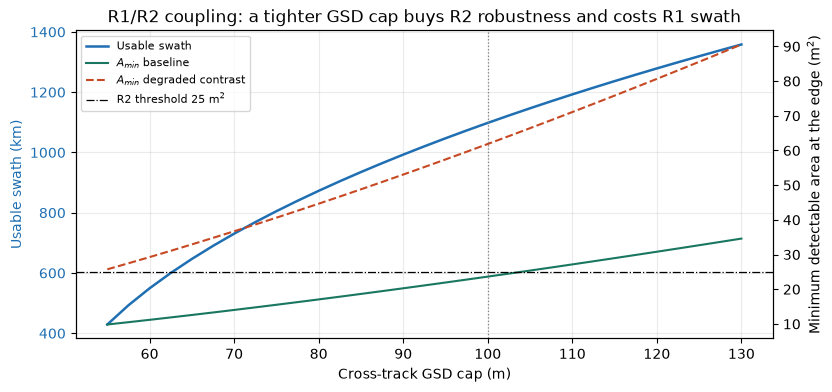

In [8]:
# The R1/R2 coupling, quantified: swath against the cross-track GSD cap  -> slides 12, 16
caps = np.arange(55, 131, 2.5)
h, gsd0 = ALT['B0'], GEOM['B0']['gsd_nadir_m']
sw, am_base, am_deg = [], [], []
for cap in caps:
    e = eta_for_cap(h, gsd0, cap, min(ETA_EDGE, eo.earth_angular_radius(h) - 1e-6))
    s = eo.off_nadir_gsd(h, gsd0, e)
    px = s['gsd_along_m'] * s['gsd_cross_m']
    sw.append(2 * eo.access_geometry(h, eta_deg=e)['ground_reach'])
    am_base.append(amin(px))
    am_deg.append(amin_degraded(px))

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(caps, sw, color='#1f6fb2', lw=1.8, label='Usable swath')
ax1.set_xlabel('Cross-track GSD cap (m)'); ax1.set_ylabel('Usable swath (km)', color='#1f6fb2')
ax1.tick_params(axis='y', labelcolor='#1f6fb2'); ax1.grid(alpha=.25)
ax2 = ax1.twinx()
ax2.plot(caps, am_base, color='#197760', lw=1.5, label='$A_{min}$ baseline')
ax2.plot(caps, am_deg, color='#c74924', lw=1.5, ls='--', label='$A_{min}$ degraded contrast')
ax2.axhline(A_FIRE_REQ_M2, color='k', lw=.9, ls='-.', label='R2 threshold 25 m$^2$')
ax2.set_ylabel('Minimum detectable area at the edge (m$^2$)')
ax2.axvline(GSD_CROSS_CAP_M, color='grey', lw=.9, ls=':')
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=8, loc='upper left')
ax1.set_title('R1/R2 coupling: a tighter GSD cap buys R2 robustness and costs R1 swath')
save_fig(fig, 'r1_r2_coupling'); plt.show()

### 3.2 R2 under the extension's altitude deviation

The extension in `orbit_planning` section 10 sweeps altitude over ±15 km and tests R1
only. R2 moves over the same range: with fixed optics the nadir GSD scales with altitude,
and `eta_for_cap` re-solves the 100 m cross-track cap, so both the pixel footprint and the
accepted view angle change with it. `geometry()` is already a closed form in altitude, so
this costs no orbit propagation.

Only a rise threatens the verdict. A lower orbit gives a finer pixel and more margin, so
the negative side is reported for completeness and the crossing is solved on the positive
side alone. Because the cap pins the edge pixel at 100 m cross-track, the edge area grows
with the nadir GSD, which is where the altitude sensitivity enters.

In [9]:
# R2 across the extension's altitude range  -> report section 7
# Magnitudes mirror ALT_SWEEP_KM in orbit_planning section 10 so the R1 and R2 results
# line up row for row. No propagation here: geometry() is closed form in altitude.
ALT_SWEEP_KM_R2 = [0.0, 0.1, 0.25, 0.5, 1.0, 2.0, 2.5, 5.0, 7.5, 10.0, 12.5, 15.0]


def r2_at(lab, dev_km):
    '''Geometry and R2 verdict at one altitude deviation from a candidate's nominal.'''
    g = geometry(ALT[lab] + dev_km)
    a_nadir, a_edge = amin(g['pixel_nadir_m2']), amin(g['pixel_edge_m2'])
    return {'Design': lab, 'Altitude dev (km)': round(dev_km, 3), 'h (km)': g['h_km'],
            'Nadir GSD (m)': g['gsd_nadir_m'], 'eta_acc (deg)': g['eta_acc_deg'],
            'Usable swath (km)': g['usable_swath_km'],
            'Edge pixel (m^2)': g['pixel_edge_m2'],
            'A_min nadir (m^2)': round(a_nadir, 2),
            'A_min edge (m^2)': round(a_edge, 2),
            'Margin edge (m^2)': round(A_FIRE_REQ_M2 - a_edge, 2),
            'Verdict': 'met' if a_edge <= A_FIRE_REQ_M2 else 'unmet'}


R2_EXT_TABLE = (pd.DataFrame([r2_at(lab, dev)
                              for lab in ('B0', 'B1')
                              for mag in ALT_SWEEP_KM_R2
                              for dev in ({0.0} if mag == 0 else {+mag, -mag})])
                .sort_values(['Design', 'Altitude dev (km)']).reset_index(drop=True))
display(R2_EXT_TABLE)
save_table(R2_EXT_TABLE, 'extension_r2_altitude')


,Design,Altitude dev (km),h (km),Nadir GSD (m),eta_acc (deg),Usable swath (km),Edge pixel (m^2),A_min nadir (m^2),A_min edge (m^2),Margin edge (m^2),Verdict
0,B0,-15.00,552.03,46.003,43.594,1097.4,6623.0,7.45,23.31,1.69,met
1,B0,-12.50,554.53,46.211,43.474,1097.6,6639.0,7.52,23.37,1.63,met
2,B0,-10.00,557.03,46.419,43.354,1097.7,6654.0,7.59,23.42,1.58,met
3,B0,-7.50,559.53,46.628,43.234,1097.8,6670.0,7.65,23.48,1.52,met
4,B0,-5.00,562.03,46.836,43.114,1097.9,6685.0,7.72,23.53,1.47,met
5,B0,-2.50,564.53,47.044,42.994,1098.0,6701.0,7.79,23.59,1.41,met
6,B0,-2.00,565.03,47.086,42.970,1098.0,6704.0,7.80,23.60,1.40,met
7,B0,-1.00,566.03,47.169,42.922,1098.1,6710.0,7.83,23.62,1.38,met
8,B0,-0.50,566.53,47.211,42.898,1098.1,6713.0,7.85,23.63,1.37,met
9,B0,-0.25,566.78,47.232,42.886,1098.1,6715.0,7.85,23.64,1.36,met


In [10]:
# Altitude at which R2 fails at the swath edge  -> report section 7
def r2_edge_amin(lab, dev_km):
    '''Minimum detectable fire area at the swath edge [m^2] for an altitude deviation.'''
    return amin(geometry(ALT[lab] + dev_km)['pixel_edge_m2'])


def r2_crossing_km(lab, hi_km=80.0, tol_km=1e-3):
    '''Common-mode altitude rise at which edge A_min reaches the R2 threshold [km].

    Bisected on the positive side only, since a lower orbit shrinks the pixel and so
    widens the margin. Returns 0.0 if R2 already fails at nominal, NaN if it still
    holds at hi_km.
    '''
    if r2_edge_amin(lab, 0.0) > A_FIRE_REQ_M2:
        return 0.0
    if r2_edge_amin(lab, hi_km) <= A_FIRE_REQ_M2:
        return float('nan')
    lo, hi = 0.0, hi_km
    while hi - lo > tol_km:
        mid = 0.5 * (lo + hi)
        if r2_edge_amin(lab, mid) <= A_FIRE_REQ_M2:
            lo = mid
        else:
            hi = mid
    return lo


R2_CROSSING_KM = {}
print(f'R2 at the swath edge against a common-mode altitude rise '
      f'(threshold {A_FIRE_REQ_M2:.0f} m^2):')
for lab in ('B0', 'B1'):
    dev = r2_crossing_km(lab)
    R2_CROSSING_KM[lab] = dev
    base = r2_edge_amin(lab, 0.0)
    g = geometry(ALT[lab] + dev)
    print(f'  {lab}: nominal A_min edge {base:5.2f} m^2 '
          f'(margin {A_FIRE_REQ_M2 - base:+.2f} m^2, '
          f'{100 * (A_FIRE_REQ_M2 - base) / A_FIRE_REQ_M2:.1f} %)')
    print(f'       reaches threshold at {dev:+.2f} km -> h {g["h_km"]:.2f} km, '
          f'nadir GSD {g["gsd_nadir_m"]:.2f} m, eta_acc {g["eta_acc_deg"]:.2f} deg, '
          f'swath {g["usable_swath_km"]:.0f} km')

print('\nThe edge pixel is pinned at the 100 m cross-track cap, so edge A_min follows the')
print('nadir GSD and therefore the altitude. Compare these crossings with the R1 altitude')
print('tolerances in orbit_planning section 10.1: whichever is smaller limits the design.')


R2 at the swath edge against a common-mode altitude rise (threshold 25 m^2):
  B0: nominal A_min edge 23.64 m^2 (margin +1.36 m^2, 5.4 %)
       reaches threshold at +64.04 km -> h 631.07 km, nadir GSD 52.59 m, eta_acc 39.83 deg, swath 1093 km
  B1: nominal A_min edge 24.38 m^2 (margin +0.62 m^2, 2.5 %)
       reaches threshold at +29.53 km -> h 631.07 km, nadir GSD 52.59 m, eta_acc 39.83 deg, swath 1093 km

The edge pixel is pinned at the 100 m cross-track cap, so edge A_min follows the
nadir GSD and therefore the altitude. Compare these crossings with the R1 altitude
tolerances in orbit_planning section 10.1: whichever is smaller limits the design.


## 4 · R3 geolocation error budget → **slides 9, 16**

Week 11: a small angular error $\delta\theta$ moves the mapped ground point by
approximately $h\,\delta\theta$ at nadir, and the two per-axis components combine in
root-sum-square for zero bias.

Off-nadir the same angular error projects through the slant range and the tilted surface,
exactly as the pixel footprint does:

$$\sigma_{along} = R_s\,\sigma_\theta, \qquad
\sigma_{cross} = \frac{R_s\,\sigma_\theta}{\sin\varepsilon}$$

The other terms: orbit position enters directly; timing enters as ground speed × $\delta t$;
and a DEM vertical error $\delta h$ displaces the intersection horizontally by
$\delta h \tan(\text{incidence})$, which vanishes at nadir.

**R3 threshold is one nadir GSD** (`reqs.ipynb` section 6), nadir-referenced so it is a
single number and the stricter reading at the swath edge.

In [11]:
def ground_speed_kms(h_km):
    '''Sub-satellite ground speed [km/s] for a circular orbit.'''
    o = eo.orbit_from_altitude(h_km, 90.0)
    return o['v'] * eo.R_E / o['a']

def angular_to_ground_m(h_km, eta_deg, sigma_rad):
    '''Ground error [m] from an equal per-axis angular uncertainty, RSS of both axes.'''
    g = eo.access_geometry(h_km, eta_deg=eta_deg)
    along = g['R_s'] * 1e3 * sigma_rad
    cross = along / math.sin(math.radians(g['eps']))
    return math.hypot(along, cross), along, cross

def budget(h_km, eta_deg, case):
    '''Full R3 error budget [m] at one altitude and view angle.'''
    b = BUDGET[case]
    g = eo.access_geometry(h_km, eta_deg=eta_deg)
    att, _, _ = angular_to_ground_m(h_km, eta_deg, b['attitude_as'] * ARCSEC)
    mnt, _, _ = angular_to_ground_m(h_km, eta_deg, b['mount_as'] * ARCSEC)
    pos = POS_PER_AXIS_M
    tim = ground_speed_kms(h_km) * 1e3 * TIMING_S
    ter = DEM_VERT_M * math.tan(math.radians(90 - g['eps']))
    total = math.sqrt(att**2 + mnt**2 + pos**2 + tim**2 + ter**2)
    return dict(attitude_m=att, mount_m=mnt, position_m=pos, timing_m=tim,
                terrain_m=ter, total_m=total)

rows = []
for lab in ('B0', 'B1'):
    h = ALT[lab]
    thr = GEOM[lab]['gsd_nadir_m']                 # R3 threshold = 1 nadir GSD
    for case in ('initial', 'refined'):
        for where, eta in (('nadir', 0.0), ('eta_acc', GEOM[lab]['eta_acc_deg'])):
            b = budget(h, eta, case)
            rows.append({'Design': lab, 'Case': case, 'Where': where,
                         'Attitude (m)': round(b['attitude_m'], 2),
                         'Mount (m)': round(b['mount_m'], 2),
                         'Position (m)': round(b['position_m'], 2),
                         'Timing (m)': round(b['timing_m'], 2),
                         'Terrain (m)': round(b['terrain_m'], 2),
                         'Total RMSE (m)': round(b['total_m'], 2),
                         'Threshold (m)': round(thr, 1),
                         'Margin (m)': round(thr - b['total_m'], 2),
                         'Verdict': 'met' if b['total_m'] <= thr else 'unmet'})
R3_TABLE = pd.DataFrame(rows)
display(R3_TABLE)
save_table(R3_TABLE, 'r3_error_budget')

,Design,Case,Where,Attitude (m),Mount (m),Position (m),Timing (m),Terrain (m),Total RMSE (m),Threshold (m),Margin (m),Verdict
0,B0,initial,nadir,38.88,27.21,3.5,6.96,0.00,48.09,47.3,-0.84,unmet
1,B0,initial,eta_acc,70.08,49.06,3.5,6.96,4.41,86.01,47.3,-38.76,unmet
2,B0,refined,nadir,7.78,7.78,3.5,6.96,0.00,13.47,47.3,33.78,met
3,B0,refined,eta_acc,14.02,14.02,3.5,6.96,4.41,21.75,47.3,25.50,met
4,B1,initial,nadir,41.24,28.87,3.5,6.91,0.00,50.94,50.1,-0.81,unmet
5,B1,initial,eta_acc,70.77,49.54,3.5,6.91,4.17,86.83,50.1,-36.71,unmet
6,B1,refined,nadir,8.25,8.25,3.5,6.91,0.00,14.00,50.1,36.13,met
7,B1,refined,eta_acc,14.15,14.15,3.5,6.91,4.17,21.86,50.1,28.27,met


### 4.1 Cross-check against slide 9

Slide 9 reports the budget for a single altitude. This model should reproduce its **nadir**
column. The off-nadir column is a separate question: slide 9's edge values are *lower* than
the projection above gives, which means a different off-nadir scaling was used there.

In [12]:
SLIDE9 = {('initial', 'nadir'): 48.11, ('initial', 'eta_acc'): 76.14,
          ('refined', 'nadir'): 13.5,  ('refined', 'eta_acc'): 19.6}
rows = []
for (case, where), quoted in SLIDE9.items():
    mine = R3_TABLE[(R3_TABLE.Design == 'B0') & (R3_TABLE.Case == case) &
                    (R3_TABLE.Where == where)]['Total RMSE (m)'].iloc[0]
    rows.append({'Case': case, 'Where': where, 'This notebook (m)': mine,
                 'Slide 9 (m)': quoted, 'Difference (m)': round(mine - quoted, 2),
                 'Difference (%)': round(100 * (mine - quoted) / quoted, 1)})
CHECK9 = pd.DataFrame(rows)
display(CHECK9)
save_table(CHECK9, 'check_vs_slide9')
print('Nadir agreement confirms the term-by-term model (attitude, mount, position, timing,')
print('terrain). The eta_acc rows disagree, so the off-nadir scaling on slide 9 differs from')
print('the Week 11 projection used here - reconcile before the report.')

,Case,Where,This notebook (m),Slide 9 (m),Difference (m),Difference (%)
0,initial,nadir,48.09,48.11,-0.02,-0.0
1,initial,eta_acc,86.01,76.14,9.87,13.0
2,refined,nadir,13.47,13.50,-0.03,-0.2
3,refined,eta_acc,21.75,19.60,2.15,11.0


Nadir agreement confirms the term-by-term model (attitude, mount, position, timing,
terrain). The eta_acc rows disagree, so the off-nadir scaling on slide 9 differs from
the Week 11 projection used here - reconcile before the report.


In [13]:
# Derived pointing requirement: how coarse can one angular term be?  -> slide 16
def solve_angle(h_km, eta_deg, threshold_m, other_as, which='attitude'):
    '''Per-axis angle [arcsec] at which the total budget reaches the threshold.'''
    lo, hi = 0.1, 60.0
    for _ in range(90):
        mid = 0.5 * (lo + hi)
        b = dict(BUDGET['refined'])
        b['attitude_as' if which == 'attitude' else 'mount_as'] = mid
        b['mount_as' if which == 'attitude' else 'attitude_as'] = other_as
        BUDGET['solve'] = b
        tot = budget(h_km, eta_deg, 'solve')['total_m']
        if tot < threshold_m:
            lo = mid
        else:
            hi = mid
    BUDGET.pop('solve', None)
    return lo

rows = []
for lab in ('B0', 'B1'):
    h, thr = ALT[lab], GEOM[lab]['gsd_nadir_m']
    for where, eta in (('nadir', 0.0), ('eta_acc', GEOM[lab]['eta_acc_deg'])):
        for which in ('attitude', 'mount'):
            a = solve_angle(h, eta, thr, 2.0, which)
            rows.append({'Design': lab, 'Where': where, 'Term': which,
                         'Other term held at (arcsec)': 2.0,
                         'Max per-axis (arcsec)': round(a, 2),
                         'Threshold (m)': round(thr, 1)})
POINTING = pd.DataFrame(rows)
display(POINTING)
save_table(POINTING, 'derived_pointing_requirement')
print('Read as a derived requirement: R3 holds while that term stays within the stated')
print('per-axis angle, with the other held at 2 arcsec.')

,Design,Where,Term,Other term held at (arcsec),Max per-axis (arcsec),Threshold (m)
0,B0,nadir,attitude,2.0,11.82,47.3
1,B0,nadir,mount,2.0,11.82,47.3
2,B0,eta_acc,attitude,2.0,6.31,47.3
3,B0,eta_acc,mount,2.0,6.31,47.3
4,B1,nadir,attitude,2.0,11.84,50.1
5,B1,nadir,mount,2.0,11.84,50.1
6,B1,eta_acc,attitude,2.0,6.68,50.1
7,B1,eta_acc,mount,2.0,6.68,50.1


Read as a derived requirement: R3 holds while that term stays within the stated
per-axis angle, with the other held at 2 arcsec.


In [14]:
for lab in ('B0', 'B1'):
    thr = GEOM[lab]['gsd_nadir_m']
    ref_nadir = R3_TABLE[(R3_TABLE.Design == lab) & (R3_TABLE.Case == 'refined') &
                         (R3_TABLE.Where == 'nadir')]['Total RMSE (m)'].iloc[0]
    ref_edge = R3_TABLE[(R3_TABLE.Design == lab) & (R3_TABLE.Case == 'refined') &
                        (R3_TABLE.Where == 'eta_acc')]['Total RMSE (m)'].iloc[0]
    record('R3', f'Threshold ({lab})', f'{thr:.1f} m (1 nadir GSD)', 'Derived',
           'One nadir GSD so position error does not exceed the resolution element', 'Wk10/Wk11')
    record('R3', f'Refined RMSE ({lab})', f'{ref_nadir:.1f} m nadir / {ref_edge:.1f} m at eta_acc',
           'Calculated', 'Small-angle projection through slant range and surface tilt, RSS', 'Wk11')
    for where in ('nadir', 'eta_acc'):
        a = amin(GEOM[lab]['pixel_nadir_m2'] if where == 'nadir' else GEOM[lab]['pixel_edge_m2'])
        record('R2', f'A_min {where} ({lab})', f'{a:.1f} m^2 vs {A_FIRE_REQ_M2:.0f} m^2',
               'Calculated geometry + slide 8 anchor',
               'Pixel-area scaling of slide 8; validated in section 3.1', 'Wk10')

SUMMARY = pd.DataFrame(ROWS)
display(SUMMARY)
save_table(SUMMARY, 'r2_r3_summary')

,ID,Quantity,Value,Tier,Basis,Lecture
0,R2,Nadir GSD (B0),47.25 m,Calculated,"Pinhole GSD = h p / f with fixed optics, scaled from the comparator",Wk10
1,R2,eta_acc (B0),42.87 deg,Calculated,Largest angle holding cross-track GSD within 100 m; limited by GSD cap (half-FOV 49.28 deg not binding),Wk10
2,R2,Pixel at eta_acc (B0),67 x 100 m,Calculated,Differential angular pixel stretch: range growth and surface tilt,Wk10
3,R2,Nadir GSD (B1),50.13 m,Calculated,"Pinhole GSD = h p / f with fixed optics, scaled from the comparator",Wk10
4,R2,eta_acc (B1),41.23 deg,Calculated,Largest angle holding cross-track GSD within 100 m; limited by GSD cap (half-FOV 49.28 deg not binding),Wk10
5,R2,Pixel at eta_acc (B1),69 x 100 m,Calculated,Differential angular pixel stretch: range growth and surface tilt,Wk10
6,R2,Diffraction adequacy,Rayleigh 25.6 m vs GSD 47 m (ratio 0.54),Calculated,"1.22 lambda h / D at 3700 nm, D = 10 cm; sampling pitch is the coarser scale, so the aperture is not limiting",Wk10
7,R3,Threshold (B0),47.3 m (1 nadir GSD),Derived,One nadir GSD so position error does not exceed the resolution element,Wk10/Wk11
8,R3,Refined RMSE (B0),13.5 m nadir / 21.8 m at eta_acc,Calculated,"Small-angle projection through slant range and surface tilt, RSS",Wk11
9,R2,A_min nadir (B0),7.9 m^2 vs 25 m^2,Calculated geometry + slide 8 anchor,Pixel-area scaling of slide 8; validated in section 3.1,Wk10


## 5 · STM entries and slide mapping → **slides 12, 14**

In [15]:
def stm(lab):
    g = GEOM[lab]
    a_edge = amin(g['pixel_edge_m2']); a_nadir = amin(g['pixel_nadir_m2'])
    ref_edge = R3_TABLE[(R3_TABLE.Design == lab) & (R3_TABLE.Case == 'refined') &
                        (R3_TABLE.Where == 'eta_acc')]['Total RMSE (m)'].iloc[0]
    ini_edge = R3_TABLE[(R3_TABLE.Design == lab) & (R3_TABLE.Case == 'initial') &
                        (R3_TABLE.Where == 'eta_acc')]['Total RMSE (m)'].iloc[0]
    thr = g['gsd_nadir_m']
    return [
        {'ID': 'R2 Detection (O1)', 'Design': lab,
         'Requirement': f'Minimum detectable fire area <= {A_FIRE_REQ_M2:.0f} m^2 for 0 <= eta <= eta_acc',
         'Design response': f"MWIR, f = {FOCAL_M*100:.1f} cm, nadir GSD {g['gsd_nadir_m']:.1f} m, "
                            f"eta_acc {g['eta_acc_deg']:.2f} deg ({g['gsd_along_m']:.0f} x {g['gsd_cross_m']:.0f} m)",
         'Performance': f'A_min {a_nadir:.1f} m^2 nadir, {a_edge:.1f} m^2 at eta_acc',
         'Margin / verdict': f"{A_FIRE_REQ_M2 - a_edge:+.1f} m^2 at the binding edge case -> "
                             f"{'met' if a_edge <= A_FIRE_REQ_M2 else 'unmet'}",
         'Robustness': f'Degraded contrast (345 K, 4 K clutter): holds only to '
                       f'{ETA_DEGRADED[lab]:.1f} deg of the {g["eta_acc_deg"]:.1f} deg '
                       f'eta_acc, so R2 at the swath edge fails under that case'},
        {'ID': 'R3 Geolocation (O2)', 'Design': lab,
         'Requirement': f'Horizontal radial RMSE <= {thr:.0f} m (1 nadir GSD) for 0 <= eta <= eta_acc',
         'Design response': f"Attitude {BUDGET['refined']['attitude_as']:.0f}\" / axis, mount "
                            f"{BUDGET['refined']['mount_as']:.0f}\" after calibration, position "
                            f"{POS_PER_AXIS_M:.1f} m, timing {TIMING_S*1e3:.0f} ms, DEM {DEM_VERT_M:.0f} m",
         'Performance': f'Initial {ini_edge:.1f} m at eta_acc; refined {ref_edge:.1f} m',
         'Margin / verdict': f"{thr - ref_edge:+.1f} m at eta_acc -> "
                             f"{'met' if ref_edge <= thr else 'unmet'} (refined); "
                             f"initial design {'met' if ini_edge <= thr else 'unmet'}",
         'Robustness': f'Derived pointing requirement in section 4.1; zero-mean independent '
                       f'errors assumed, no within-orbit thermal variation modelled'},
    ]

STM = pd.DataFrame([r for lab in ('B0', 'B1') for r in stm(lab)])
display(STM.set_index(['ID', 'Design']).T)
save_table(STM, 'stm_r2_r3')

ID,R2 Detection (O1),R3 Geolocation (O2),R2 Detection (O1),R3 Geolocation (O2)
Design,B0,B0,B1,B1
Requirement,Minimum detectable fire area <= 25 m^2 for 0 <= eta <= eta_acc,Horizontal radial RMSE <= 47 m (1 nadir GSD) for 0 <= eta <= eta_acc,Minimum detectable fire area <= 25 m^2 for 0 <= eta <= eta_acc,Horizontal radial RMSE <= 50 m (1 nadir GSD) for 0 <= eta <= eta_acc
Design response,"MWIR, f = 18.0 cm, nadir GSD 47.3 m, eta_acc 42.87 deg (67 x 100 m)","Attitude 2"" / axis, mount 2"" after calibration, position 3.5 m, timing 1 ms, DEM 4 m","MWIR, f = 18.0 cm, nadir GSD 50.1 m, eta_acc 41.23 deg (69 x 100 m)","Attitude 2"" / axis, mount 2"" after calibration, position 3.5 m, timing 1 ms, DEM 4 m"
Performance,"A_min 7.9 m^2 nadir, 23.6 m^2 at eta_acc",Initial 86.0 m at eta_acc; refined 21.8 m,"A_min 8.8 m^2 nadir, 24.4 m^2 at eta_acc",Initial 86.8 m at eta_acc; refined 21.9 m
Margin / verdict,+1.4 m^2 at the binding edge case -> met,+25.5 m at eta_acc -> met (refined); initial design unmet,+0.6 m^2 at the binding edge case -> met,+28.3 m at eta_acc -> met (refined); initial design unmet
Robustness,"Degraded contrast (345 K, 4 K clutter): holds only to 19.3 deg of the 42.9 deg eta_acc, so R2 at the swath edge fail...","Derived pointing requirement in section 4.1; zero-mean independent errors assumed, no within-orbit thermal variation...","Degraded contrast (345 K, 4 K clutter): holds only to 12.1 deg of the 41.2 deg eta_acc, so R2 at the swath edge fail...","Derived pointing requirement in section 4.1; zero-mean independent errors assumed, no within-orbit thermal variation..."


In [16]:
SLIDE_MAP = pd.DataFrame([
    ('7  Payload and imaging (trade)', 'imaging_geometry',
     'Section 2: GSD and eta_acc per candidate; the thermal-vs-visual trade itself is not computed here'),
    ('8  Payload and imaging (selected)', 'imaging_geometry, gsd_vs_view_angle, r2_detection',
     'Sections 2-3: f, nadir GSD, pixel at eta_acc, A_min nadir and edge with margins'),
    ('9  Geolocation', 'r3_error_budget, check_vs_slide9',
     'Section 4: term-by-term budget, initial vs refined, nadir vs eta_acc, and the slide 9 cross-check'),
    ('12 Decision and STM', 'stm_r2_r3',
     'Section 5: R2 and R3 rows for both candidates'),
    ('14 Complete STM', 'stm_r2_r3, r2_r3_summary',
     'Section 5 plus the basis column from reqs.ipynb'),
    ('16 Payload / geolocation detail', 'derived_pointing_requirement, r1_r2_coupling',
     'Sections 3-4: degraded-contrast limit, derived pointing requirement, R1/R2 coupling figure'),
], columns=['Slide', 'Saved artefacts', 'What to take from this notebook'])
display(SLIDE_MAP)
save_table(SLIDE_MAP, 'slide_map')
print('R1 access -> orbit_planning.ipynb, slides 5, 6, 10, 11, 12, 15')
print('Requirement thresholds and basis -> reqs.ipynb, slide 4')

,Slide,Saved artefacts,What to take from this notebook
0,7 Payload and imaging (trade),imaging_geometry,Section 2: GSD and eta_acc per candidate; the thermal-vs-visual trade itself is not computed here
1,8 Payload and imaging (selected),"imaging_geometry, gsd_vs_view_angle, r2_detection","Sections 2-3: f, nadir GSD, pixel at eta_acc, A_min nadir and edge with margins"
2,9 Geolocation,"r3_error_budget, check_vs_slide9","Section 4: term-by-term budget, initial vs refined, nadir vs eta_acc, and the slide 9 cross-check"
3,12 Decision and STM,stm_r2_r3,Section 5: R2 and R3 rows for both candidates
4,14 Complete STM,"stm_r2_r3, r2_r3_summary",Section 5 plus the basis column from reqs.ipynb
5,16 Payload / geolocation detail,"derived_pointing_requirement, r1_r2_coupling","Sections 3-4: degraded-contrast limit, derived pointing requirement, R1/R2 coupling figure"


R1 access -> orbit_planning.ipynb, slides 5, 6, 10, 11, 12, 15
Requirement thresholds and basis -> reqs.ipynb, slide 4


## Limitations

- **R2 is not an independent radiometric calculation.** It scales slide 8's reported
  minimum detectable area by pixel area. Section 3.1 validates that scaling against two
  external results, but the underlying Planck radiance, pixel fill, noise root-sum-square
  and the SNR ≥ 5 rule are inherited, not re-derived.
- The noise terms, fire and background temperatures, the detection threshold and the DEM,
  star-tracker, GNSS and timing accuracies are all assumed inputs (see `reqs.ipynb`).
- R3 assumes zero-mean, mutually independent errors. Thermal cycling couples attitude and
  mount alignment in practice, and pixel quantisation is excluded.
- The off-nadir error projection disagrees with slide 9's edge column; the two models must
  be reconciled before either is reported as final.
- Pinhole optics, spherical Earth, no atmospheric refraction, no MTF or algorithm model.
  The "detected" verdict rests on the assumed SNR threshold.
- The 100 m cross-track GSD cap that defines η_acc is an assumed group choice, not derived.